## SETUP

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/drive/MyDrive/SEMESTER 7/Penerapan Kecerdasan Artifisial/dataset")
print(DATA_DIR)

/content/drive/MyDrive/SEMESTER 7/Penerapan Kecerdasan Artifisial/dataset


In [ ]:
!pip install ultralytics

In [ ]:
import random
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
import json

## EDA

In [ ]:
images = [p for p in DATA_DIR.iterdir() if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]]

print("Jumlah gambar:", len(images))

Jumlah gambar: 563


In [ ]:
data = []

for path in images:
    try:
        timestamp = pd.to_datetime(
            path.stem,
            format="%d_%m_%Y_%H-%M-%S"
        )

        data.append({
            "image": path.name,
            "timestamp": timestamp,
            "date": timestamp.date(),
            "hour": timestamp.hour
        })

    except ValueError:
        print("Format tidak sesuai:", path.name)

df = pd.DataFrame(data)
df

Format tidak sesuai: 29_09_2026_22-13-17 (1).jpg
Format tidak sesuai: 29_09_2026_22-13-43 (1).jpg
Format tidak sesuai: 29_09_2026_22-52-44 (1).jpg
Format tidak sesuai: 29_09_2026_22-53-23 (1).jpg


,image,timestamp,date,hour
0,22_09_2026_16-12-50.jpg,2026-09-22 16:12:50,2026-09-22,16
1,22_09_2026_16-12-59.jpg,2026-09-22 16:12:59,2026-09-22,16
2,22_09_2026_16-13-12.jpg,2026-09-22 16:13:12,2026-09-22,16
3,22_09_2026_16-13-16.jpg,2026-09-22 16:13:16,2026-09-22,16
4,22_09_2026_16-12-47.jpg,2026-09-22 16:12:47,2026-09-22,16
...,...,...,...,...
554,09_11_2026_11-31-37.jpg,2026-11-09 11:31:37,2026-11-09,11
555,09_11_2026_11-17-48.jpg,2026-11-09 11:17:48,2026-11-09,11
556,09_11_2026_11-17-31.jpg,2026-11-09 11:17:31,2026-11-09,11
557,09_11_2026_11-16-39.jpg,2026-11-09 11:16:39,2026-11-09,11


In [ ]:
hour_counts = df["hour"].value_counts().sort_index()
hour_counts

,count
hour,
0,22
1,20
2,20
3,20
4,22
5,20
6,21
7,28
8,23


In [ ]:
from collections import Counter

sizes = Counter(Image.open(p).size for p in images)

for size, count in sizes.most_common(10):
    print(size, count)

(1344, 756) 117
(1170, 2532) 28
(1204, 676) 11
(1339, 751) 10
(1336, 751) 9
(1201, 676) 7
(1204, 679) 7
(1206, 676) 7
(1339, 753) 6
(1203, 676) 6


## PREPROCESSING

### Normalisasi

In [ ]:
TARGET_W = 1333
TARGET_H = 750


def resize_with_right_padding(img, target_size=(1333, 750)):
    target_w, target_h = target_size
    w, h = img.size

    scale = target_h / h
    new_w = int(w * scale)
    new_h = target_h

    img = img.resize((new_w, new_h))

    if new_w > target_w:
        scale = target_w / new_w
        new_w = target_w
        new_h = int(new_h * scale)
        img = img.resize((new_w, new_h))

    canvas = Image.new("RGB", (target_w, target_h), "black")

    canvas.paste(img, (0, 0))

    return canvas

### ROI

In [ ]:
def get_roi(img):
    h, w = img.shape[:2]

    roi = [
        (0.00, 0.50),
        (0.60, 0.20),
        (0.65, 0.20),
        (0.60, 1.00),
        (0.00, 1.00)
    ]

    return [(int(x * w), int(y * h)) for x, y in roi]

In [ ]:
import random

RAW_DIR = Path("/content/drive/MyDrive/SEMESTER 7/Penerapan Kecerdasan Artifisial/dataset")

files = list(RAW_DIR.glob("*"))
img_path = random.choice(files)

img = Image.open(img_path).convert("RGB")

img = resize_with_right_padding(
    img,
    (TARGET_W, TARGET_H)
)

img_np = np.array(img)

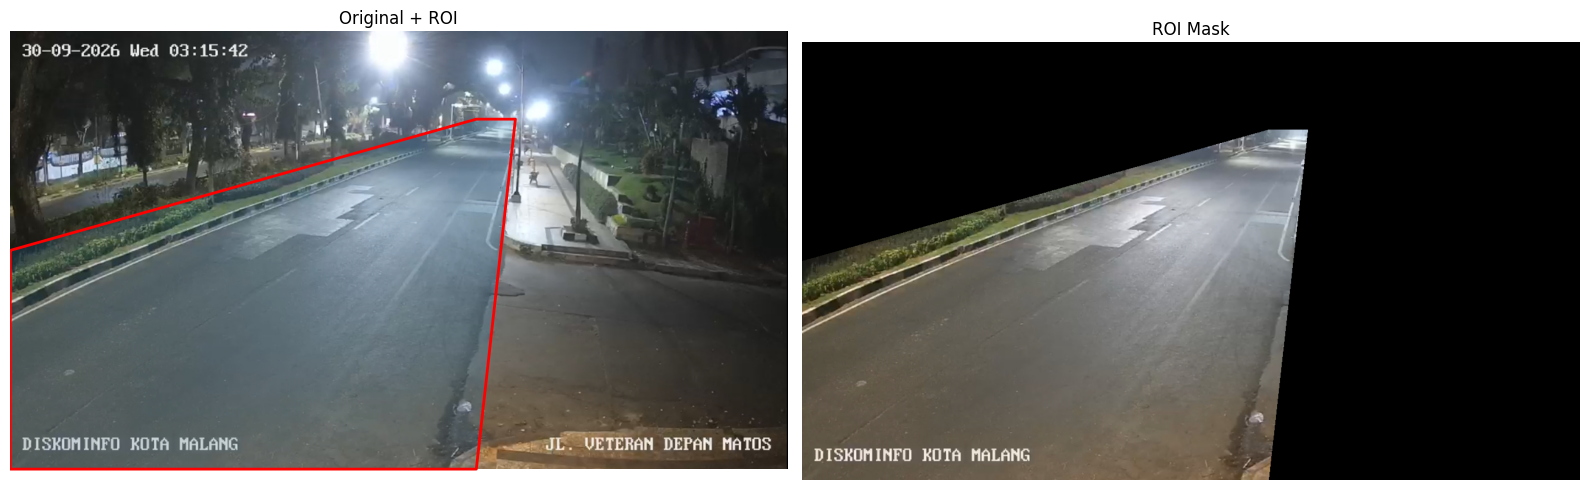

In [ ]:
img_np = np.array(img)

ROI = get_roi(img_np)

points = ROI + [ROI[0]]
xs, ys = zip(*points)

import cv2

mask = np.zeros(img_np.shape[:2], dtype=np.uint8)

roi_points = np.array(ROI, dtype=np.int32)
cv2.fillPoly(mask, [roi_points], 255)

roi_img = cv2.bitwise_and(img_np, img_np,mask=mask)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Original + ROI
axes[0].imshow(img_np)
axes[0].plot(xs, ys, "r-", linewidth=2)
axes[0].fill(xs, ys, alpha=0.2)
axes[0].set_title("Original + ROI")
axes[0].axis("off")

# Hasil masking
axes[1].imshow(roi_img)
axes[1].set_title("ROI Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## OBJECT DETECTION

In [ ]:
from ultralytics import YOLO
import numpy as np
import cv2
import matplotlib.pyplot as plt

model = YOLO("yolo11m.pt")

vehicle_classes = {
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck"
}

In [ ]:
def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

In [ ]:
def overlap_ratio(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])

    smaller = min(area1, area2)
    return inter / smaller if smaller > 0 else 0

In [ ]:
CONF = 0.10
IMGSZ = 1280
MIN_AREA = 600
IOU_THRESHOLD = 0.4
OVERLAP_THRESHOLD = 0.6


def detect_vehicles(img_path):

    # 1. Load + resize
    img = Image.open(img_path).convert("RGB")
    img = resize_with_right_padding(img, (TARGET_W, TARGET_H))
    img_np = np.array(img)

    # 2. ROI: dipakai buat filter posisi box, bukan buat mask input model
    ROI = get_roi(img_np)
    roi_points = np.array(ROI, dtype=np.int32)

    mask = np.zeros(img_np.shape[:2], dtype=np.uint8)
    cv2.fillPoly(mask, [roi_points], 255)

    roi_img = cv2.bitwise_and(img_np, img_np, mask=mask)

    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    brightness = gray[mask > 0].mean()

    # 3. YOLO di gambar penuh
    results = model(
        img_np,
        conf=CONF,
        imgsz=IMGSZ,
        classes=list(vehicle_classes.keys()),
        verbose=False
    )

    result = results[0]

    boxes = result.boxes.xyxy.cpu().numpy()
    confidences = result.boxes.conf.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)

    # 4. Buang box yang titik tengah-bawahnya di luar ROI
    if len(boxes) > 0:
        contour = roi_points.reshape(-1, 1, 2)

        inside = np.array([
            cv2.pointPolygonTest(
                contour,
                (float((b[0] + b[2]) / 2), float(b[3])),
                False
            ) >= 0
            for b in boxes
        ])

        boxes = boxes[inside]
        confidences = confidences[inside]
        classes = classes[inside]

    # 5. Minimum bounding-box area
    if len(boxes) > 0:
        areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
        valid = areas >= MIN_AREA

        boxes = boxes[valid]
        confidences = confidences[valid]
        classes = classes[valid]

    # 6. Overlap filtering
    order = np.argsort(confidences)[::-1]
    remove = set()

    for i in range(len(order)):
        idx1 = order[i]

        if idx1 in remove:
            continue

        for j in range(i + 1, len(order)):
            idx2 = order[j]

            if idx2 in remove:
                continue

            box1 = boxes[idx1]
            box2 = boxes[idx2]

            if (
                calculate_iou(box1, box2) >= IOU_THRESHOLD
                or overlap_ratio(box1, box2) >= OVERLAP_THRESHOLD
            ):
                remove.add(idx2)

    return {
        "roi_img": roi_img,
        "boxes": boxes,
        "confidences": confidences,
        "classes": classes,
        "remove": remove,
        "brightness": brightness,
        "conf": CONF
    }

Gambar jam 08 yang valid: 23


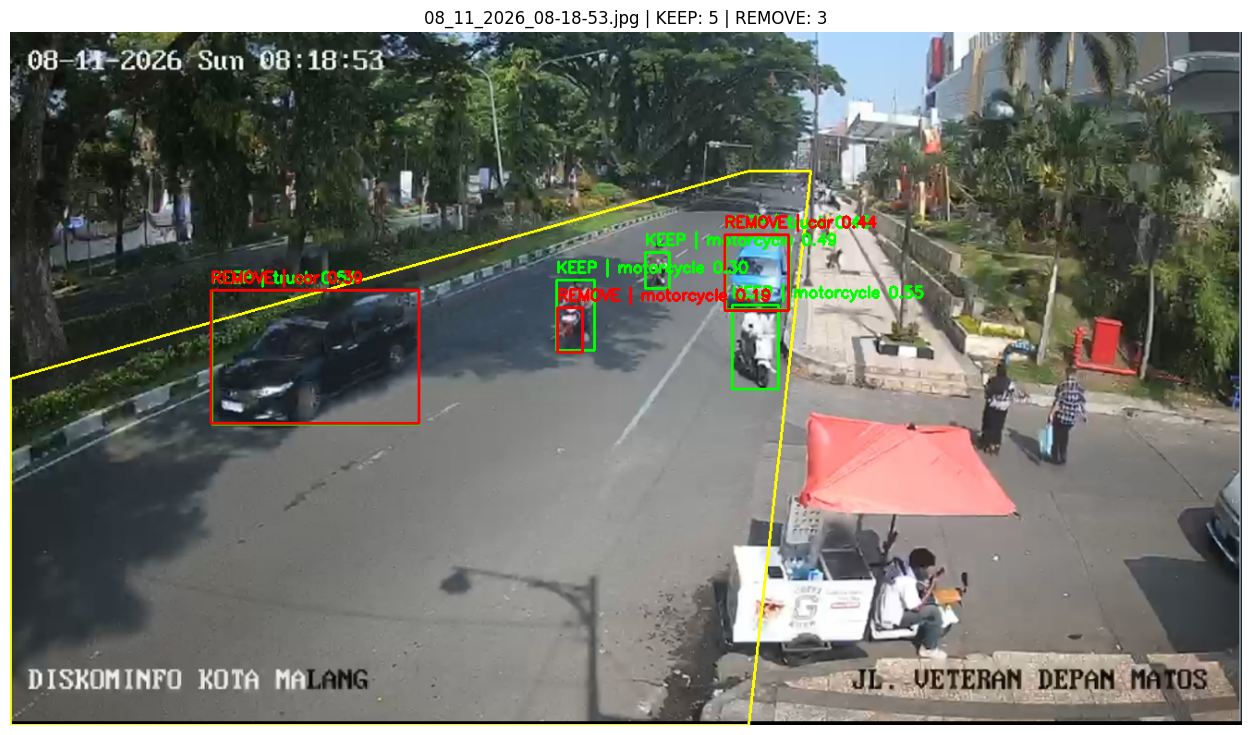

In [ ]:
TARGET_HOUR = 8

images_hour = [
    p for p in images
    if pd.to_datetime(p.stem, format="%d_%m_%Y_%H-%M-%S", errors="coerce").hour == TARGET_HOUR
]

def can_open(p):
    try:
        with Image.open(p) as im:
            im.verify()
        return True
    except Exception:
        return False

images_hour = [p for p in images_hour if can_open(p)]
print(f"Gambar jam {TARGET_HOUR:02d} yang valid: {len(images_hour)}")

img_path = random.choice(images_hour)

detection = detect_vehicles(img_path)

boxes = detection["boxes"]
confidences = detection["confidences"]
classes = detection["classes"]
remove = detection["remove"]

img = resize_with_right_padding(Image.open(img_path).convert("RGB"), (TARGET_W, TARGET_H))
output = np.array(img)

roi_pts = np.array(get_roi(output), dtype=np.int32)
cv2.polylines(output, [roi_pts], True, (255, 255, 0), 2)

for i in range(len(boxes)):

    x1, y1, x2, y2 = boxes[i].astype(int)

    class_name = vehicle_classes[classes[i]]
    score = confidences[i]

    if i in remove:
        color = (255, 0, 0)
        status = "REMOVE"
    else:
        color = (0, 255, 0)
        status = "KEEP"

    cv2.rectangle(output, (x1, y1), (x2, y2), color, 2)

    cv2.putText(
        output,
        f"{status} | {class_name} {score:.2f}",
        (x1, max(y1 - 8, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        color,
        2
    )

n_keep = len(boxes) - len(remove)

plt.figure(figsize=(16, 9))
plt.imshow(output)
plt.axis("off")
plt.title(f"{img_path.name} | KEEP: {n_keep} | REMOVE: {len(remove)}")
plt.show()

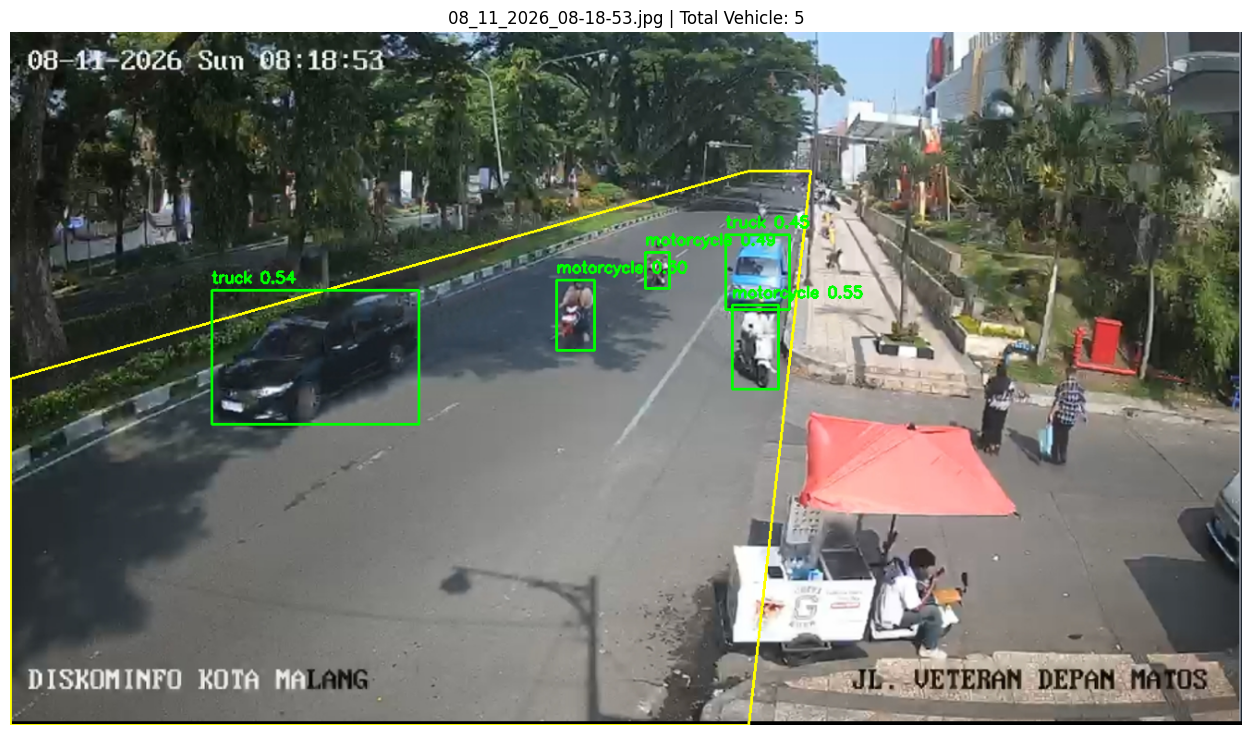

In [ ]:
img = resize_with_right_padding(Image.open(img_path).convert("RGB"), (TARGET_W, TARGET_H))
final_output = np.array(img)

cv2.polylines(final_output, [roi_pts], True, (255, 255, 0), 2)

for i in range(len(boxes)):

    if i in remove:
        continue

    x1, y1, x2, y2 = boxes[i].astype(int)

    class_name = vehicle_classes[classes[i]]
    score = confidences[i]

    cv2.rectangle(final_output, (x1, y1), (x2, y2), (0, 255, 0), 2)

    cv2.putText(
        final_output,
        f"{class_name} {score:.2f}",
        (x1, max(y1 - 8, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(16, 9))
plt.imshow(final_output)
plt.axis("off")
plt.title(f"{img_path.name} | Total Vehicle: {n_keep}")
plt.show()

## VEHICLE COUNTING

In [ ]:
from pathlib import Path
import pandas as pd

RAW_DIR = Path("/content/drive/MyDrive/SEMESTER 7/Penerapan Kecerdasan Artifisial/dataset")
OUTPUT_CSV = Path("/content/drive/MyDrive/SEMESTER 7/Penerapan Kecerdasan Artifisial/vehicle_counting.csv")

image_files = sorted([
    f for f in RAW_DIR.iterdir()
    if f.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
])

results_data = []

for img_path in image_files:

    print(f"Processing: {img_path.name}")

    try:
        timestamp = pd.to_datetime(img_path.stem, format="%d_%m_%Y_%H-%M-%S")
    except ValueError:
        print(f"  -> Format nama file tidak sesuai, dilewati: {img_path.name}")
        continue

    detection = detect_vehicles(img_path)

    boxes = detection["boxes"]
    classes = detection["classes"]
    remove = detection["remove"]

    counts = {"car": 0, "motorcycle": 0, "bus": 0, "truck": 0}

    for i in range(len(boxes)):
        if i in remove:
            continue
        counts[vehicle_classes[classes[i]]] += 1

    results_data.append({
        "image": img_path.name,
        "timestamp": timestamp,
        "date": timestamp.date(),
        "hour": timestamp.hour,
        "brightness": round(detection["brightness"], 2),
        "conf": detection["conf"],
        "car": counts["car"],
        "motorcycle": counts["motorcycle"],
        "bus": counts["bus"],
        "truck": counts["truck"],
        "total_vehicle": sum(counts.values())
    })

df = pd.DataFrame(results_data).sort_values("timestamp").reset_index(drop=True)

df.to_csv(OUTPUT_CSV, index=False)

print("\nSELESAI")
print(f"Jumlah gambar : {len(df)}")
print(f"Output        : {OUTPUT_CSV}")

display(df)

Processing: 01_10_2026_01-29-45.png
Processing: 01_10_2026_01-30-19.png
Processing: 01_10_2026_01-31-54.png
Processing: 01_10_2026_01-32-06.png
Processing: 04_10_2026_03-56-32.png
Processing: 04_10_2026_04-02-34.png
Processing: 04_11_2026_04-02-56.png
Processing: 04_11_2026_04-13-56.png
Processing: 04_11_2026_04-14-10.png
Processing: 04_11_2026_04-14-42.png
Processing: 04_11_2026_04-28-31.png
Processing: 04_11_2026_04-30-11.png
Processing: 04_11_2026_04-32-14.png
Processing: 04_11_2026_04-37-14.png
Processing: 04_11_2026_04-40-35.png
Processing: 04_11_2026_04-41-02.png
Processing: 04_11_2026_04-46-24.png
Processing: 04_11_2026_04-46-42.png
Processing: 04_11_2026_21-02-59.png
Processing: 04_11_2026_21-03-25.png
Processing: 04_11_2026_21-03-45.png
Processing: 04_11_2026_21-21-43.png
Processing: 04_11_2026_21-21-55.png
Processing: 04_11_2026_21-22-26.png
Processing: 04_11_2026_21-41-39.png
Processing: 04_11_2026_21-42-14.png
Processing: 04_11_2026_22-42-24.png
Processing: 04_11_2026_22-45

,image,timestamp,date,hour,brightness,conf,car,motorcycle,bus,truck,total_vehicle
0,07_11_2016_21-15-18.png,2016-11-07 21:15:18,2016-11-07,21,42.90,0.1,0,0,0,0,0
1,07_09_2026_18-36-40.png,2026-09-07 18:36:40,2026-09-07,18,124.45,0.1,3,0,0,1,4
2,08_09_2026_01-04-42.png,2026-09-08 01:04:42,2026-09-08,1,105.71,0.1,1,2,0,0,3
3,10_09_2026_20-46-25.png,2026-09-10 20:46:25,2026-09-10,20,98.50,0.1,2,0,0,0,2
4,10_09_2026_20-46-43.png,2026-09-10 20:46:43,2026-09-10,20,109.74,0.1,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
554,09_11_2026_14-09-03.jpg,2026-11-09 14:09:03,2026-11-09,14,88.09,0.1,3,0,0,0,3
555,09_11_2026_14-32-58.jpg,2026-11-09 14:32:58,2026-11-09,14,86.22,0.1,4,0,0,0,4
556,09_11_2026_14-33-43.jpg,2026-11-09 14:33:43,2026-11-09,14,88.41,0.1,4,1,0,1,6
557,09_11_2026_14-35-33.jpg,2026-11-09 14:35:33,2026-11-09,14,87.12,0.1,3,3,0,1,7


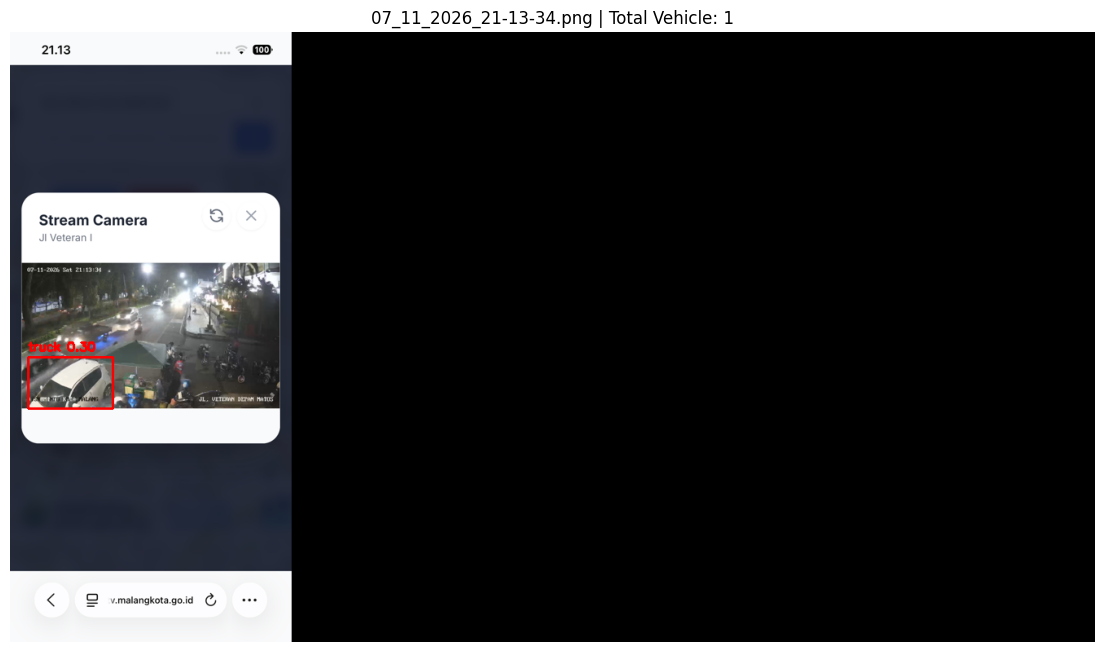

In [ ]:
row = df.sample(1).iloc[0]

img_path = RAW_DIR / row["image"]
detection = detect_vehicles(img_path)

img = Image.open(img_path).convert("RGB")
img = resize_with_right_padding(img, (TARGET_W, TARGET_H))
img = np.array(img)

for i, box in enumerate(detection["boxes"]):

    if i in detection["remove"]:
        continue

    x1, y1, x2, y2 = map(int, box)
    class_name = vehicle_classes[detection["classes"][i]]
    score = detection["confidences"][i]

    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)

    cv2.putText(
        img,
        f"{class_name} {score:.2f}",
        (x1, max(y1 - 8, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(14, 8))
plt.imshow(img)
plt.axis("off")
plt.title(f"{row['image']} | Total Vehicle: {row['total_vehicle']}")
plt.show()

## ANALYTICS

### Traffic Density

In [ ]:
q1, q3 = df["total_vehicle"].quantile([0.25, 0.75])

def get_density(total):
    if total <= q1:
        return "Sepi"
    if total <= q3:
        return "Sedang"
    return "Ramai"

df["density"] = df["total_vehicle"].apply(get_density)

### Peak Hour

In [ ]:
hourly = (
    df.groupby("hour")["total_vehicle"]
    .agg(["mean", "count"])
    .reset_index()
)
hourly = hourly[hourly["count"] >= 3]

peak_hours = hourly.nlargest(3, "mean")["hour"].tolist()

In [ ]:
thresholds = {
    "q1": float(q1),
    "q3": float(q3),
    "peak_hours": [int(h) for h in peak_hours],
    "hourly_mean": {
        int(h): round(float(m), 2)
        for h, m in zip(hourly["hour"], hourly["mean"])
    },
}

THRESHOLD_JSON = OUTPUT_CSV.parent / "thresholds.json"

with open(THRESHOLD_JSON, "w") as f:
    json.dump(thresholds, f, indent=2)

print(f"Q1 = {q1}, Q3 = {q3}")
print(f"Peak hours: {thresholds['peak_hours']}")
print(df["density"].value_counts())
print(f"Disimpan: {THRESHOLD_JSON}")

Q1 = 1.0, Q3 = 5.0
Peak hours: [15, 16, 6]
density
Sedang    251
Sepi      178
Ramai     130
Name: count, dtype: int64
Disimpan: /content/drive/MyDrive/SEMESTER 7/Penerapan Kecerdasan Artifisial/thresholds.json
